# Eksploracja danych — brakujące wartości

**Cel zajęć:** nauczyć się *znajdować* braki (także te ukryte), *diagnozować*, czy są przypadkowe, i *świadomie wybierać*, czy je usunąć, czy uzupełnić.

**Plan:**
1. Rozgrzewka na zbiorze **Titanic** — te same kroki co na wykładzie.
2. Zadanie główne: **oferty mieszkań** (`nieruchomosci.csv`) — prawdziwy bałagan.

**Zadania:** 🟢 podstawowe (obowiązkowe), 🔵 dla ambitnych.

**Jak pracować:** w Colabie wybierz *Plik → Zapisz kopię na Dysku*, wgraj plik `nieruchomosci.csv` (ikona folderu po lewej → *Prześlij*), rozwiąż zadania w miejscach `# TODO`, a gotowy notatnik umieść w swoim repozytorium na GitHubie.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams.update({"figure.figsize": (7, 4), "font.size": 11})

URL_TITANIC = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
titanic = pd.read_csv("titanic.csv") if Path("titanic.csv").exists() else pd.read_csv(URL_TITANIC)

if not Path("nieruchomosci.csv").exists():
    print("⚠️ Wgraj plik nieruchomosci.csv do bieżącego katalogu (w Colabie: ikona folderu → Prześlij).")

print(titanic.shape)
titanic.head()

(891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


---
# Część 1. Rozgrzewka: Titanic

| kolumna | znaczenie |
|---|---|
| `Survived` | czy pasażer przeżył (1 = tak) |
| `Pclass` | klasa biletu (1, 2, 3) |
| `Sex`, `Age` | płeć, wiek |
| `SibSp`, `Parch` | liczba rodzeństwa/małżonków oraz rodziców/dzieci na pokładzie |
| `Fare` | cena biletu (£) |
| `Cabin` | numer kabiny |
| `Embarked` | port zaokrętowania: C — Cherbourg, Q — Queenstown, S — Southampton |

### 🟢 Zadanie 1: ile jest braków?

1. Policz liczbę i odsetek braków w każdej kolumnie. Pokaż tylko kolumny, w których braki występują, posortowane malejąco.
2. Narysuj poziomy wykres słupkowy odsetka braków (`.plot.barh()`), z opisem osi.

          Liczba braków  Odsetek [%]
Cabin               687    77.104377
Age                 177    19.865320
Embarked              2     0.224467


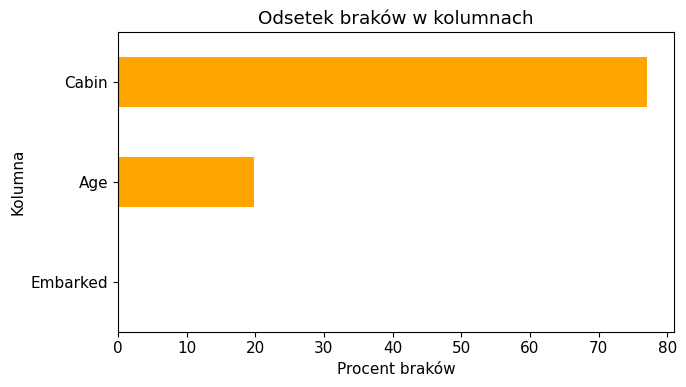

In [2]:
# TODO
# 1
braki_liczba = titanic.isna().sum()
braki_odsetek = titanic.isna().mean() * 100

df_braki = pd.DataFrame({
    'Liczba braków': braki_liczba,
    'Odsetek [%]': braki_odsetek
})

df_braki = df_braki[df_braki['Liczba braków'] > 0].sort_values(by='Liczba braków', ascending=False)
print(df_braki)

# 2
df_braki['Odsetek [%]'].sort_values().plot.barh(color='orange')
plt.title('Odsetek braków w kolumnach')
plt.xlabel('Procent braków')
plt.ylabel('Kolumna')
plt.tight_layout()
plt.show()


### 🟢 Zadanie 2: mapa braków

Narysuj mapę braków (`sns.heatmap(titanic.isna(), cbar=False)`) dla kolumn `Age`, `Cabin`, `Embarked` — najpierw z wierszami w oryginalnej kolejności, a potem **posortowanymi według klasy** (`Pclass`). Dwa wykresy obok siebie.

Co widać na drugim wykresie, czego nie było widać na pierwszym?

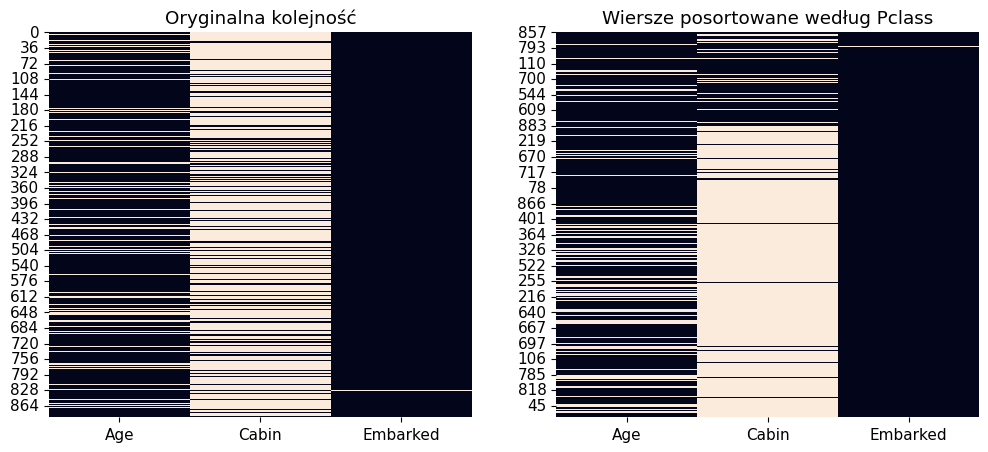

In [3]:
kolumny = ["Age", "Cabin", "Embarked"]

# TODO
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
sns.heatmap(titanic[kolumny].isna(), cbar=False, ax=ax[0])
ax[0].set_title('Oryginalna kolejność')

kolejnosc = titanic.sort_values('Pclass')
sns.heatmap(kolejnosc[kolumny].isna(), cbar=False, ax=ax[1])
ax[1].set_title('Wiersze posortowane według Pclass')

plt.show()

*Twoja odpowiedź:*  
Na drugim wykresie po posortowaniu z użyciem 'Pclass' wyraźnie widać, że braki danych w kolumnie Cabin tworzą wzór. Jasny obszar oznacza brak danych i jest on zgrupowany w dolnej, większej części wykresu, która odpowiada 2 i 3 klasie pasażerów. W górnej części wykresu (odpowiadającej 1 klasie pasażerów) dane o kolumnie Cabin pojawiają się częściej. Na pierwszym wykresie, bez sortowania, te same braki wydawały się one po prostu przypadkowo rozproszone.

### 🟢 Zadanie 3: czy braki wieku są losowe?

1. Utwórz serię `brak_wieku = titanic["Age"].isna()`.
2. Policz odsetek braków wieku w każdej klasie i osobno dla każdej płci.
3. Porównaj odsetek ocalałych wśród osób ze znanym wiekiem i bez wieku.
4. Narysuj wyniki z punktów 2 i 3 na dwóch wykresach słupkowych.
5. Czy braki wieku to MCAR? Co by się stało z odsetkiem ocalałych, gdybyśmy usunęli wiersze bez wieku?

Odsetek braków wieku w każdej klasie: 
Pclass
1    13.888889
2     5.978261
3    27.698574
Name: Age, dtype: float64

Odsetek braków wieku według płci: 
Sex
female    16.878981
male      21.490468
Name: Age, dtype: float64

Odsetek ocalałych: 
wiek znany    40.616246
brak wieku    29.378531
Name: Survived, dtype: float64


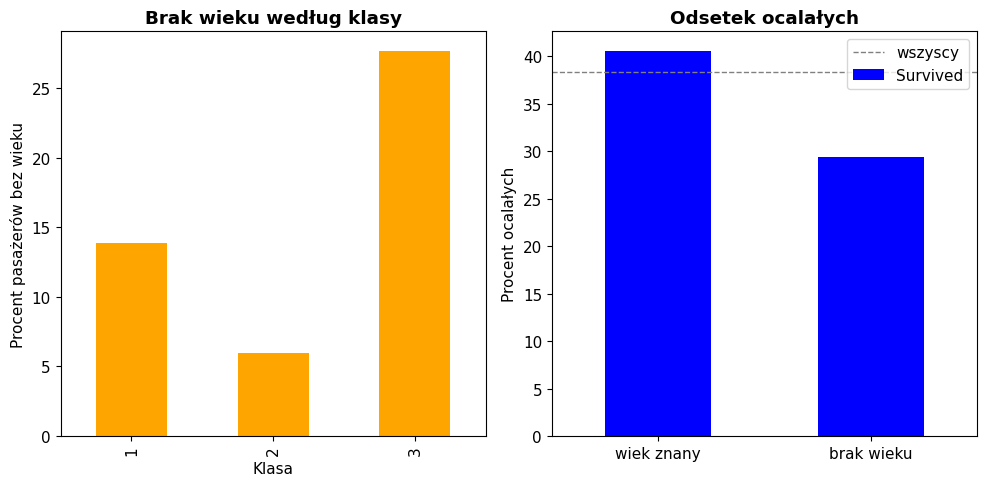

In [4]:
brak_wieku = titanic["Age"].isna()

# TODO
# 2
braki_klasa = brak_wieku.groupby(titanic["Pclass"]).mean() * 100
braki_plec = brak_wieku.groupby(titanic["Sex"]).mean() * 100

print(f"Odsetek braków wieku w każdej klasie: \n{braki_klasa}")
print(f"\nOdsetek braków wieku według płci: \n{braki_plec}")

# 3
ocalali = titanic.groupby(brak_wieku)["Survived"].mean() * 100
ocalali.index = ["wiek znany", "brak wieku"]
print(f"\nOdsetek ocalałych: \n{ocalali}")

# 4
fig, ax = plt.subplots(1, 2, figsize=(10, 5))
braki_klasa.plot.bar(ax=ax[0], color='orange')
ax[0].set_title('Brak wieku według klasy', fontweight='bold')
ax[0].set_xlabel('Klasa')
ax[0].set_ylabel('Procent pasażerów bez wieku')

ocalali.plot.bar(ax=ax[1], color='blue')
ax[1].set_title('Odsetek ocalałych', fontweight='bold')
ax[1].set_ylabel('Procent ocalałych')
ax[1].axhline(titanic["Survived"].mean() * 100, color='gray', linestyle='--', linewidth=1, label="wszyscy")
ax[1].tick_params(axis='x', rotation=0)
ax[1].legend()

plt.tight_layout()
plt.show()


*Twoja odpowiedź:*  
Braki wieku nie są losowe (to nie jest MCAR). Z analizy wynika, że w 3 klasie wieku brakuje ok. 4.6 razy częściej niż w klasie 2. Dodatkowo osoby bez wieku przeżywały znacznie rzadziej (29.4%) niż te z udokumentowanym wiekiem (40.6%). Usunięcie wierszy bez wieku zawyżyłoby ogólny odsetek osób ocalałych w naszym zbiorze danych.

### 🟢 Zadanie 4: ile kosztuje usuwanie?

Dla czterech wariantów — bez zmian, `dropna(subset=["Embarked"])`, `dropna(subset=["Age"])`, `dropna()` — zbuduj tabelę z kolumnami:
- liczba wierszy,
- odsetek ocalałych,
- odsetek pasażerów 1. klasy.

Który wariant najbardziej zniekształca dane i dlaczego?

In [5]:
warianty = {
    "bez zmian": titanic,
    "subset=['Embarked']": titanic.dropna(subset=["Embarked"]),
    "subset=['Age']": titanic.dropna(subset=["Age"]),
    "dropna()": titanic.dropna()
}

# TODO: tabela
wyniki = []
for nazwa, df in warianty.items():
    wyniki.append({
        "Wariant": nazwa,
        "Liczba wierszy": len(df),
        "Odsetek ocalałych [%]": df["Survived"].mean() * 100,
        "Odsetek pasażerów z 1. klasy [%]": (df["Pclass"] == 1).mean() * 100 
    })

df_wyniki = pd.DataFrame(wyniki).set_index("Wariant")
print(df_wyniki)

                     Liczba wierszy  Odsetek ocalałych [%]  \
Wariant                                                      
bez zmian                       891              38.383838   
subset=['Embarked']             889              38.245219   
subset=['Age']                  714              40.616246   
dropna()                        183              67.213115   

                     Odsetek pasażerów z 1. klasy [%]  
Wariant                                                
bez zmian                                   24.242424  
subset=['Embarked']                         24.071991  
subset=['Age']                              26.050420  
dropna()                                    86.338798  


*Twoja odpowiedź:*  
Najbardziej zniekształca wariant dropna(). Po tym wariancie z 891 wierszy zostaje 183 wiersze. Odsetek ocalałych rośnie z 38% do 67%, a odsetek pasażerów 1. klasy rośnie z 24% do 86%. Wynika to z tego, że usunięcie wszystkich wierszy z jakimkolwiek brakiem eliminuje głównie pasażerów 2. i 3. klasy, którzy najczęściej nie mieli podanego numeru kabiny.

### 🟢 Zadanie 5: uzupełnianie wieku

1. **Najpierw** dodaj kolumnę-flagę `Age_brak`.
2. Utwórz dwie wersje kolumny wieku:
   - `wiek_srednia` — braki uzupełnione średnią,
   - `wiek_grupy` — braki uzupełnione medianą w grupach (klasa × płeć); wskazówka: `groupby(...)["Age"].transform("median")`.
3. Narysuj trzy histogramy obok siebie (te same przedziały, `bins=np.arange(0, 82, 2)`): znane wartości, `wiek_srednia`, `wiek_grupy`.
4. Porównaj odchylenia standardowe. Która metoda bardziej zniekształca rozkład?

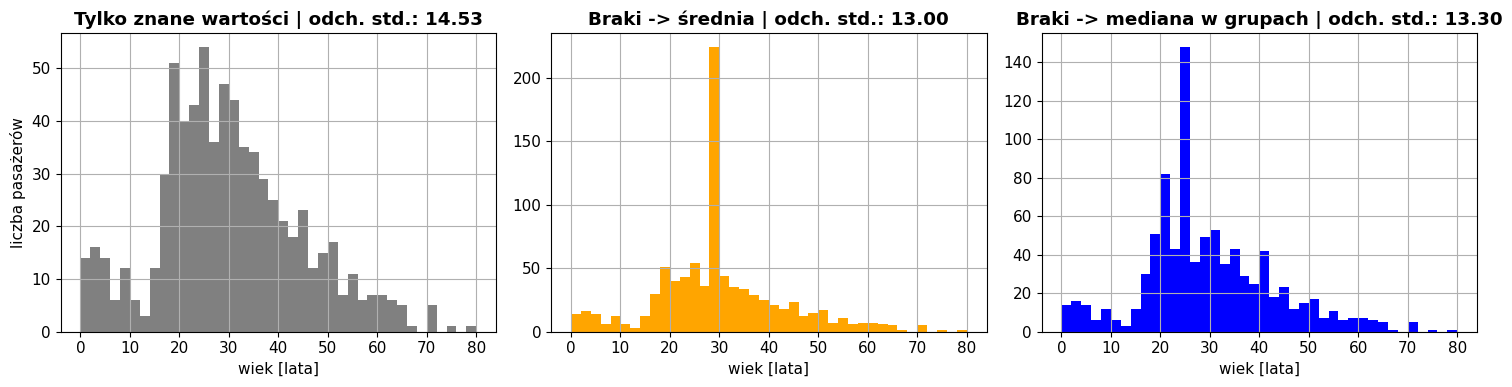

In [6]:
# TODO
# 1
titanic['Age_brak'] = titanic['Age'].isna()

# 2
wiek_srednia = titanic['Age'].fillna(titanic['Age'].mean())
wiek_grupy = titanic['Age'].fillna(titanic.groupby(['Pclass', 'Sex'])['Age'].transform('median'))

# 3
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
bins = np.arange(0, 82, 2)

titanic['Age'].dropna().hist(bins=bins, ax=ax[0], color='gray')
ax[0].set_title(f"Tylko znane wartości | odch. std.: {titanic['Age'].std():.2f}", fontweight='bold')
ax[0].set_xlabel('wiek [lata]')
ax[0].set_ylabel('liczba pasażerów')

wiek_srednia.hist(bins=bins, ax=ax[1], color='orange')
ax[1].set_title(f"Braki -> średnia | odch. std.: {wiek_srednia.std():.2f}", fontweight='bold')
ax[1].set_xlabel('wiek [lata]')

wiek_grupy.hist(bins=bins, ax=ax[2], color='blue')
ax[2].set_title(f"Braki -> mediana w grupach | odch. std.: {wiek_grupy.std():.2f}", fontweight='bold')
ax[2].set_xlabel('wiek [lata]')

plt.tight_layout()
plt.show()

*Twoja odpowiedź:*  
4) Rozkład najbardziej zniekształca proste uzupełnianie średnią. Metoda ta tworzy na histogramie sztuczny "słup", czyli blisko 180 osób z wiekiem ok. 29.7 oraz znacznie zaniża zmienność, obniżając odchylenie standardowe z 14.53 do 13.00 (uzupełnianie medianą w grupach obniża ją mniej bo do 13.30).

### 🔵 Zadanie 6 (dla ambitnych): imputacja modelem

Uzupełnij wiek za pomocą `IterativeImputer` z biblioteki scikit-learn, wykorzystując kolumny `Pclass`, `SibSp`, `Parch`, `Fare` oraz płeć zakodowaną jako 0/1. Porównaj histogram i odchylenie standardowe z wynikami zadania 5.

```python
from sklearn.experimental import enable_iterative_imputer  # wymagane!
from sklearn.impute import IterativeImputer
```

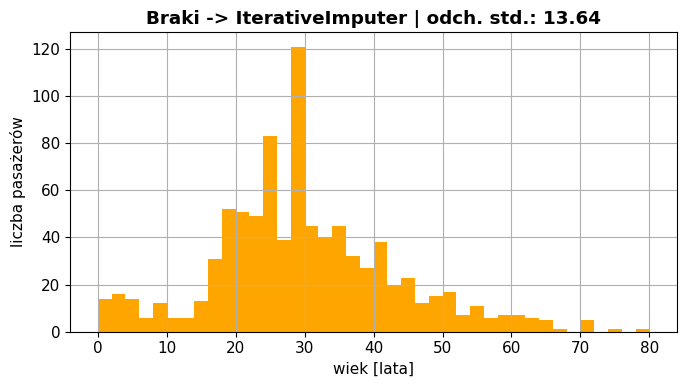

In [7]:
# TODO
from sklearn.experimental import enable_iterative_imputer  # wymagane!
from sklearn.impute import IterativeImputer

titanic['Sex_num'] = titanic["Sex"].map({"male": 0, "female": 1})

cechy = ['Pclass', 'SibSp', 'Parch', 'Fare', 'Sex_num', 'Age']

imputer = IterativeImputer(random_state=42)
uzupelnione = imputer.fit_transform(titanic[cechy])

titanic['Age_iterative'] = uzupelnione[:, 5]

std_iterative = titanic['Age_iterative'].std() 

plt.figure(figsize=(7, 4))
bins = np.arange(0, 82, 2)
titanic['Age_iterative'].hist(bins=bins, color='orange')
plt.title(f"Braki -> IterativeImputer | odch. std.: {std_iterative:.2f}", fontweight='bold')
plt.xlabel('wiek [lata]')
plt.ylabel('liczba pasażerów')
plt.tight_layout()
plt.show()


**Odpowiedź**:  
Uzupełnienie braków za pomocą modelu do imputacji zapobiega tworzeniu sztucznych "słupów" na histogramie, ponieważ model szacuje wiek indywidualnie. Dzięki temu odchylenie standardowe jest wyższe niż przy prostym uzupełnianiu średnią lub medianą (zadanie 5), co oznacza, że model lepiej zachowuje naturalną zmienność danych.

---
# Część 2. Zadanie główne: oferty mieszkań

**Dane:** plik `nieruchomosci.csv` — 45 ofert sprzedaży mieszkań w pięciu miastach.

| kolumna | znaczenie |
|---|---|
| `powierzchnia` | powierzchnia mieszkania [m²] |
| `rok_budowy` | rok budowy budynku |
| `pietro`, `liczba_pieter` | piętro mieszkania (0 = parter) i liczba pięter budynku |
| `parking`, `balkon` | Tak / Nie |
| `stan` | stan mieszkania |
| `cena_m2`, `cena_total` | cena za m² i cena całkowita [zł] |

Plik przygotował ktoś, kto różne braki zapisywał na różne sposoby. Twoim zadaniem jest je znaleźć i rozsądnie obsłużyć.

### 🟢 Zadanie 7: pierwszy rzut oka

1. Wczytaj plik bez żadnych dodatkowych parametrów i sprawdź typy kolumn (`dtypes`).
2. Policz braki (`isna().sum()`). Ile braków widzi pandas?
3. Dlaczego kolumna `powierzchnia` nie jest liczbowa, choć zawiera powierzchnię w m²?

In [8]:
mieszkania = pd.read_csv("nieruchomosci.csv")

# TODO
# 1
print(f'Typy kolumn: \n{mieszkania.dtypes}')

# 2
print(f'\nLiczba braków w kolumnach: \n{mieszkania.isna().sum()}')

Typy kolumn: 
id                int64
miasto           object
dzielnica        object
powierzchnia     object
liczba_pokoi      int64
rok_budowy       object
pietro           object
liczba_pieter     int64
parking          object
balkon           object
stan             object
cena_m2           int64
cena_total        int64
dtype: object

Liczba braków w kolumnach: 
id               0
miasto           0
dzielnica        0
powierzchnia     4
liczba_pokoi     0
rok_budowy       4
pietro           0
liczba_pieter    0
parking          0
balkon           0
stan             0
cena_m2          0
cena_total       0
dtype: int64


*Twoja odpowiedź:*  
2) Pandas widzi tylko te braki, które są puste lub zapisane jako NaN.  
3) Kolumna powierzchnia nie jest liczbowa, ponieważ zostały wpisane do niej tekstowe oznaczenia braków np. "brak". Obecność chociaż jednej wartości tekstowej powoduje, że pandas traktuje całą kolumnę jako ciąg znaków, a nie liczby, stąd kolumna powierzchnia ma typ object, a nie typ liczbowy.

### 🟢 Zadanie 8: braki „w przebraniu”

1. Dla każdej kolumny tekstowej i każdej kolumny liczbowej obejrzyj występujące wartości (`value_counts(dropna=False)` albo `unique()`). Wypisz wszystkie wartości, które oznaczają brak.
2. **Pułapka:** w kolumnach `powierzchnia` i `pietro` występuje `0`. Czy w obu przypadkach to brak danych?
3. Wczytaj plik ponownie z parametrem `na_values` podanym jako **słownik** (kolumna → lista wartości), tak aby każda kolumna miała tylko „swoje” oznaczenia braków.
4. Sprawdź typy kolumn i policz braki jeszcze raz.

In [9]:
# TODO 1
for k in mieszkania.columns:
    print(f"----{k}----")
    print(mieszkania[k].unique())

----id----
[ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24
 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45]
----miasto----
['Warszawa' 'Kraków' 'Wrocław' 'Poznań' 'Gdańsk']
----dzielnica----
['Mokotów' 'Krowodrza' 'Krzyki' 'Grunwald' 'Wrzeszcz' 'Śródmieście'
 'Podgórze' 'Stare Miasto' 'Jeżyce' 'Oliwa' 'Żoliborz' 'Kazimierz'
 'Psie Pole' 'Rataje' 'Siedlce' 'Praga' 'Nowa Huta' 'Fabryczna' 'Wilda'
 'Przymorze' 'Ochota' 'Bronowice' 'Centrum' 'Ursynów' 'Dębniki' 'Zaspa'
 'Wilanów' 'Łagiewniki' 'Biskupin' 'Sołacz' 'Chełm' 'Bielany' 'Ruczaj'
 'Gaj' 'Główna' 'Morena' 'Targówek' 'Mistrzejowice' 'Ołbin' 'Piątkowo'
 'Suchanino']
----powierzchnia----
['65' '48' '72' '55' '80' nan '60' '45' '70' '90' '58' '52' '68' '0' '75'
 '62' '50' 'brak' '66' '85' '54' '95' '56' '42' '78' '88' '64' '51' '69'
 '46' '82' '76']
----liczba_pokoi----
[3 2 4 1 5]
----rok_budowy----
['2015' nan '2010' '2018' '1998' '2020' '2005' '2019' 'brak' '2001' '2016'
 '1995' '2012' '2017'

*Twoja odpowiedź:*  
Wartość 0 w kolumnie 'powierzchnia' to z pewnością brak danych lub błąd, ponieważ mieszkanie nie może mieć zerowego metrażu.   
Z kolei 0 w kolumnie 'pietro' oznacza parter (wynika to z opisu zadania 0=parter), więc jest to pełnoprawna i poprawna wartość, a nie brak.

In [10]:
braki_slownik = {
    "powierzchnia": ["brak", "0"],
    # TODO: pozostałe kolumny
    "rok_budowy": ["brak"],
    "pietro": ["brak", "-999"],
    "parking": ["?"],
    "balkon": ["?"],
    "cena_m2": [-1, -999]
}

mieszkania = pd.read_csv("nieruchomosci.csv", na_values=braki_slownik)
# TODO: typy i liczba braków
print(f'Typy kolumn: \n{mieszkania.dtypes}')
print(f'\nLiczba braków w kolumnach: \n{mieszkania.isna().sum()}')

Typy kolumn: 
id                 int64
miasto            object
dzielnica         object
powierzchnia     float64
liczba_pokoi       int64
rok_budowy       float64
pietro           float64
liczba_pieter      int64
parking           object
balkon            object
stan              object
cena_m2          float64
cena_total         int64
dtype: object

Liczba braków w kolumnach: 
id               0
miasto           0
dzielnica        0
powierzchnia     9
liczba_pokoi     0
rok_budowy       7
pietro           3
liczba_pieter    0
parking          5
balkon           3
stan             0
cena_m2          2
cena_total       0
dtype: int64


### 🟢 Zadanie 9: dziwna kategoria

Obejrzyj wartości w kolumnie `stan`. Jedna z nich nie pasuje do pozostałych. Co mogła oznaczać i jak ją poprawić? Zaproponuj i zastosuj rozwiązanie (uzasadnij je).

In [11]:
# TODO
mieszkania["stan"] = mieszkania["stan"].replace("很好", "Bardzo dobry")

**Odpowiedź**:  
Chińskie znaki '很好' są wartością, która nie pasuje do pozostałych. Tłumacząc na język polski oznaczają 'bardzo dobry'. Najlepszym rozwiązaniem jest zastąpienie ich wartością 'Bardzo dobry', która już istnieje w tej kolumnie, aby ujednolicić zbiór danych bez utraty informacji.

### 🟢 Zadanie 10: mapa braków

1. Narysuj odsetek braków w kolumnach (wykres słupkowy) i mapę braków.
2. Czy braki w różnych kolumnach występują w tych samych wierszach? (Wskazówka: `mieszkania.isna().corr()` dla kolumn z brakami.)

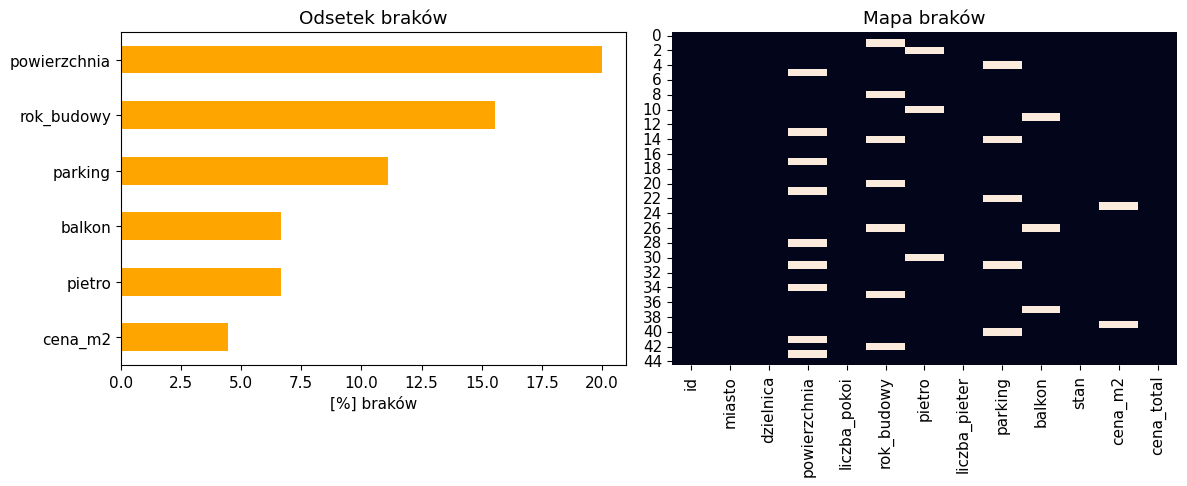

Korelacja występowania braków: 
              powierzchnia  rok_budowy    pietro       parking    balkon  \
powierzchnia  1.000000e+00   -0.214599 -0.133631 -4.170558e-17 -0.133631   
rok_budowy   -2.145988e-01    1.000000 -0.114708  4.335550e-02  0.131095   
pietro       -1.336306e-01   -0.114708  1.000000 -9.449112e-02 -0.071429   
parking      -4.170558e-17    0.043355 -0.094491  1.000000e+00 -0.094491   
balkon       -1.336306e-01    0.131095 -0.071429 -9.449112e-02  1.000000   
cena_m2      -1.078328e-01   -0.092563 -0.057639 -7.624929e-02 -0.057639   

               cena_m2  
powierzchnia -0.107833  
rok_budowy   -0.092563  
pietro       -0.057639  
parking      -0.076249  
balkon       -0.057639  
cena_m2       1.000000  


In [12]:
# TODO
# 1
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

odsetek_brakow = mieszkania.isna().mean() * 100
odsetek_brakow[odsetek_brakow > 0].sort_values().plot.barh(color='orange', ax=ax[0])
ax[0].set_title('Odsetek braków')
ax[0].set_xlabel('[%] braków')

sns.heatmap(mieszkania.isna(), cbar=False, ax=ax[1])
ax[1].set_title('Mapa braków')

plt.tight_layout()
plt.show()

# 2
braki_kolumny = mieszkania.columns[mieszkania.isna().any()]
korelacja = mieszkania[braki_kolumny].isna().corr()
print(f"Korelacja występowania braków: \n{korelacja}")

*Twoja odpowiedź:*  
2) W celu sprawdzenia, czy braki występuja w tych samych wierszach, musimy spojrzeć na macierz korelacji. Jeśli mamy wartości równe 1.0 lub bliskie 1 dla pary kolumn, oznacza to, że braki w obu tych kolumnach pojawiają się równocześnie w tych samych wierszach.

### 🟢 Zadanie 11: odtwórz, zamiast zgadywać

Sprawdź, czy dla wierszy bez braków zachodzi zależność `cena_total = powierzchnia × cena_m2`. Jeśli tak — wykorzystaj ją, żeby **odtworzyć** brakujące wartości w kolumnach `powierzchnia` i `cena_m2`. Ile braków udało się w ten sposób usunąć?

To jest „ręczne uzupełnianie” z wykładu: znamy prawdziwą wartość, więc nie musimy jej szacować.

In [13]:
# TODO
pelne_dane = mieszkania.dropna(subset=['cena_total', 'powierzchnia', 'cena_m2'])
zaleznosc = (pelne_dane['cena_total'] == pelne_dane['powierzchnia'] * pelne_dane['cena_m2']).all()
print(f"Czy zależność zachodzi dla wszystkich kompletnych wierszy? {zaleznosc}")

braki_przed = mieszkania[['powierzchnia', 'cena_m2']].isna().sum().sum()

mieszkania['powierzchnia'] = mieszkania['powierzchnia'].fillna(mieszkania['cena_total'] / mieszkania['cena_m2'])

mieszkania['cena_m2'] = mieszkania['cena_m2'].fillna(mieszkania['cena_total'] / mieszkania['powierzchnia'])

braki_po = mieszkania[['powierzchnia', 'cena_m2']].isna().sum().sum()
print(f" Liczba braków przed wypełnieniem: {braki_przed}")
print(f" Liczba braków po wypełnieniu: {braki_po}")

odtworzone = braki_przed - braki_po
print(f" Liczba odtworzonych brakujących wartości: {odtworzone}")


Czy zależność zachodzi dla wszystkich kompletnych wierszy? True
 Liczba braków przed wypełnieniem: 11
 Liczba braków po wypełnieniu: 0
 Liczba odtworzonych brakujących wartości: 11


### 🟢 Zadanie 12: pozostałe braki

Dla każdej z kolumn `rok_budowy`, `pietro`, `parking`, `balkon`:
1. **Najpierw** dodaj kolumnę-flagę braku (np. `rok_budowy_brak`).
2. Zdecyduj, co zrobić z brakami, i zaimplementuj decyzję. Do rozważenia:
   - `rok_budowy` — mediana całościowa czy mediana w grupach? Jakie grupy mają sens: `miasto` czy `stan`? Policz mediany w obu podziałach, zanim wybierzesz.
   - `pietro` — są tylko 3 braki; mediana, a może coś mądrzejszego (np. środkowe piętro budynku: `liczba_pieter // 2`)?
   - `parking`, `balkon` — dominanta czy osobna kategoria `"nieznane"`? Co się stanie z odsetkiem mieszkań z parkingiem w każdym z tych wariantów?
3. Sprawdź, że w zbiorze nie ma już braków.

In [14]:
# TODO
# 1
kolumny_braki = ['rok_budowy', 'pietro', 'parking', 'balkon']
for k in kolumny_braki:
    mieszkania[f"{k}_brak"] = mieszkania[k].isna()

# 2
print(f"Mediany 'rok_budowy' według 'miasto': \n{mieszkania.groupby('miasto')['rok_budowy'].median()}")
print(f"\nMediany 'rok_budowy' według 'stan': \n{mieszkania.groupby('stan')['rok_budowy'].median()}")

mieszkania['rok_budowy'] = mieszkania['rok_budowy'].fillna(mieszkania.groupby('stan')['rok_budowy'].transform('median'))

mieszkania['pietro'] = mieszkania['pietro'].fillna(mieszkania['liczba_pieter'] // 2)

mieszkania['parking'] = mieszkania['parking'].fillna('nieznane')
mieszkania['balkon'] = mieszkania['balkon'].fillna('nieznane')

# 3
print(f"\nLiczba braków w całym zbiorze danych: \n{mieszkania.isna().sum()}")

Mediany 'rok_budowy' według 'miasto': 
miasto
Gdańsk      2001.5
Kraków      2013.0
Poznań      2013.5
Warszawa    2015.0
Wrocław     2011.0
Name: rok_budowy, dtype: float64

Mediany 'rok_budowy' według 'stan': 
stan
Bardzo dobry    2019.0
Do remontu      1997.0
Dobry           2010.0
Name: rok_budowy, dtype: float64

Liczba braków w całym zbiorze danych: 
id                 0
miasto             0
dzielnica          0
powierzchnia       0
liczba_pokoi       0
rok_budowy         0
pietro             0
liczba_pieter      0
parking            0
balkon             0
stan               0
cena_m2            0
cena_total         0
rok_budowy_brak    0
pietro_brak        0
parking_brak       0
balkon_brak        0
dtype: int64


**Odpowiedź**:  
rok_budowy: zastosowano medianę w grupach według kolumny 'stan', ponieważ stan mieszkania (np. 'Dobry') znacznie lepiej różnicuje wiek budynków niż ogólny podział na miasta.  
pietro: użyliśmy wartości środkowego piętra (liczba_pieter // 2), ponieważ gwarantuje nam to, że nie przypiszemy np. 10 piętra dla 4-piętrowego bloku, co mogłoby się stać przy użyciu mediany całościowej.  
parking i balkon: uzupełnione zostały wartością 'nieznane', ponieważ zastąpienie braków dominantą (np. 'Tak') sztucznie zawyżyłoby odsetek mieszkań z parkingiem, zaburzając proporcje w analizie.

### 🟢 Zadanie 13: porównaj przed i po

Wczytaj surowy plik jeszcze raz (z `na_values` z zadania 8) i porównaj z oczyszczoną wersją:
1. statystyki opisowe kolumn `powierzchnia`, `rok_budowy`, `cena_m2` (`describe()`),
2. histogram `rok_budowy` przed i po uzupełnieniu (dwa wykresy obok siebie, te same przedziały).

Czy uzupełnianie zmieniło rozkłady w istotny sposób?

Statystyki opisowe przed uzupełnieniem: 
       powierzchnia   rok_budowy       cena_m2
count     36.000000    38.000000     43.000000
mean      64.638889  2010.289474  10223.255814
std       13.684512     7.828941   1611.689030
min       42.000000  1995.000000   8200.000000
25%       54.750000  2004.250000   9000.000000
50%       63.000000  2011.500000   9800.000000
75%       72.750000  2016.750000  11100.000000
max       95.000000  2022.000000  15000.000000

Statystyki opisowe po uzupełnieniu: 
       powierzchnia   rok_budowy       cena_m2
count     45.000000    45.000000     45.000000
mean      64.933333  2010.644444  10244.336043
std       12.755391     7.407476   1623.857997
min       42.000000  1995.000000   8200.000000
25%       56.000000  2006.000000   9000.000000
50%       62.000000  2011.000000   9800.000000
75%       72.000000  2017.000000  11200.000000
max       95.000000  2022.000000  15000.000000


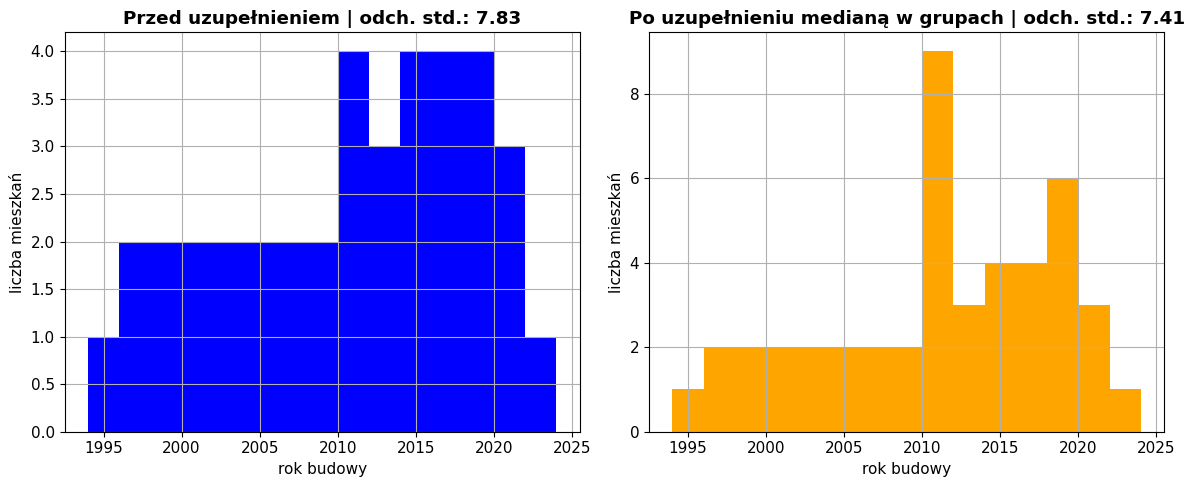

In [15]:
# TODO
# 1
surowy_plik = pd.read_csv("nieruchomosci.csv", na_values=braki_slownik)
kolumny = ['powierzchnia', 'rok_budowy', 'cena_m2']

print(f"Statystyki opisowe przed uzupełnieniem: \n{surowy_plik[kolumny].describe()}")
print(f"\nStatystyki opisowe po uzupełnieniu: \n{mieszkania[kolumny].describe()}")

# 2
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
bins = np.arange(1994, 2026, 2)

surowy_plik['rok_budowy'].dropna().hist(bins=bins, ax=ax[0], color='blue')
ax[0].set_title(f"Przed uzupełnieniem | odch. std.: {surowy_plik['rok_budowy'].std():.2f}", fontweight='bold')
ax[0].set_xlabel('rok budowy')
ax[0].set_ylabel('liczba mieszkań')

mieszkania['rok_budowy'].hist(bins=bins, ax=ax[1], color='orange')
ax[1].set_title(f"Po uzupełnieniu medianą w grupach | odch. std.: {mieszkania['rok_budowy'].std():.2f}", fontweight='bold')
ax[1].set_xlabel('rok budowy')
ax[1].set_ylabel('liczba mieszkań')

plt.tight_layout()
plt.show()

*Twoja odpowiedź:*  
Rozkłady nie uległy drastycznej zmianie. Wartości 'powierzchnia' i 'cena_m2' zostały precyzyjnie odtworzone z matematycznej zależności, więc są w pełni wiarygodne. Z kolei uzupełnienie 'rok_budowy' medianą w grupach wygenerowało niewielkie lokalne 'pliki', ale zachowała naturalny kształ rozkładu znacznie lepiej, niż zrobiłaby to globalna średnia.

### 🟢 Zadanie 14: zapisz decyzje

Uzupełnij tabelę. Dobra analiza danych to taka, którą ktoś inny może odtworzyć.

| Kolumna | Jak zapisano braki | Liczba braków | Decyzja | Uzasadnienie |
|---|---|---|---|---|
| `powierzchnia` | 'brak', '0', NaN | 9 | odtworzenie ze wzoru | Wyliczenie dokładnej wartości z proporcji 'cena_total' / 'cena_m2' zamiast szacowania. |
| `cena_m2` | -1, -999 | 2 | odtworzenie ze wzoru | Dokładna wartość wyliczona z proporcji 'cena_total' / 'powierzchnia' |
| `rok_budowy` | 'brak', NaN | 7 | mediana w grupach wedlug stanu | Zachowuje naturalny rozkład lepiej niż globalna średnia. |
| `pietro` | 'brak', -999 | 3 | liczba_pieter // 2 | Unikamy przypisania piętra wyższego niż budynek. |
| `parking` | '?' | 5 | nowa kategoria 'nieznane' | Zapobiega sztucznemu zawyżeniu odsetka mieszkań z parkingiem. |
| `balkon` | '?' | 3 | nowa kategoria 'nieznane' | Chroni proporcje danych przed zniekształceniem danych. |
| `stan` | '很好' | 0 | zamiana '很好' na 'Bardzo dobry' | Ujednolicenie z istniejącą kategorią bez utraty danych. |

### 🔵 Zadanie 15 (dla ambitnych): czy wybór metody ma znaczenie?

Uzupełnij `rok_budowy` na trzy sposoby: medianą całościową, medianą w grupach według miasta i medianą w grupach według stanu. Dla każdego wariantu policz korelację `rok_budowy` z `cena_m2`. Który wariant najmniej zmienia korelację w porównaniu z danymi bez braków?

In [19]:
# TODO
surowy_plik = pd.read_csv("nieruchomosci.csv", na_values=braki_slownik)

korelacja_bazowa = surowy_plik['rok_budowy'].corr(surowy_plik['cena_m2'])

rok_budowy_mediana = surowy_plik['rok_budowy'].fillna(surowy_plik['rok_budowy'].median())
rok_budowy_miasto = surowy_plik['rok_budowy'].fillna(surowy_plik.groupby('miasto')['rok_budowy'].transform('median'))
rok_budowy_stan = surowy_plik['rok_budowy'].fillna(surowy_plik.groupby('stan')['rok_budowy'].transform('median'))

print(f"Korelacja bazowa (bez braków):       {korelacja_bazowa:.4f}")
print(f"Mediana całościowa:                  {rok_budowy_mediana.corr(surowy_plik['cena_m2']):.4f}")
print(f"Mediana według miast:                {rok_budowy_miasto.corr(surowy_plik['cena_m2']):.4f}")
print(f"Mediana według stanu:                {rok_budowy_stan.corr(surowy_plik['cena_m2']):.4f}")

Korelacja bazowa (bez braków):       0.6872
Mediana całościowa:                  0.6557
Mediana według miast:                0.6909
Mediana według stanu:                0.6890


*Twoja odpowiedź:*  
Najmniej korelację zmienia wariant z medianą w grupach według stanu. Otrzymany wynik dla tego wariantu (0.6890) jest najbliżej korelacji bazowej (0.6872). Natomiast mediana całościowa najbardziej zniekształca korelację obniżając ją do 0.6557.

### Eksperyment z LLM typu Bielik

Wyniki wygenerowane przez model Bielik znacząco różnią się od rozwiązań zaprezentowanych w poprzednich zadaniach. Model zaproponował bardzo ogólne metody, pomijając specyficzne zależności ukryte w zbiorze.

1. Model nie dostrzega relacji matematycznych i zamiast użyć wzoru ('cena_total' /  'cena_m2'), aby obliczyć błędną powierzchnię, model po prostu zalecił usunięcie tych wierszy, co prowadzi do utraty danych.  
2. LLM zalecał wstawienie tekstu (np. 'Brak danych') do kolumn liczbowych 'rok_budowy', co zepsułoby typ danych w Pandas i zablokowało obliczenia, podczas gdy my użyliśmy bezpiecznej mediany w grupach.  
3. Model zignorował chińskie znaki ('很好'), które wymagały ujednolicenia na 'Bardzo dobry', a zamiast tego zaproponował, zmianę stanów na kody np. bardzo dobry -> A.  

Podsumowując model świetnie się sprawdza do znajdowania niespójności w formatach, ale ostateczne decyzje dotyczące imputacji, dedukcji braków i zachowania rozkładów muszą opierać się na ludzkiej logice.